Saving plasma_G2_10min_FINAL.csv to plasma_G2_10min_FINAL.csv

File uploaded:
plasma_G2_10min_FINAL.csv

DATASET STRUCTURE
Rows: 1686
Columns: 10

Columns:
- _id
- __v
- createdAt
- datetime
- doorStatus
- dsTemperature
- humidity
- time_slot
- username
- interval_min

VALIDATION
Invalid datetime: 0
Invalid temperature: 0
Valid observations: 1686

TEMPORAL COVERAGE
N observations: 1686
Start: 2026-09-08 21:50:11+00:00
End: 2026-09-23 02:30:01+00:00
Duration: 340.6639 hours
Duration: 14.1943 days
Median interval: 10.0 min
Mean interval: 12.1305 min
Minimum interval: 3.3333 min
Maximum interval: 2886.6667 min

SAMPLING REGULARITY
Intervals evaluated: 1685
Intervals within 8-12 min: 1675
Percentage within nominal regime: 99.4065 %
Median absolute deviation from 10 min: 0.0 min
95th percentile absolute deviation from 10 min: 0.0167 min

GAP / MISSING-DATA ANALYSIS
Gap threshold: 15.0 min
Number of gaps: 5
Estimated missing observations: 362
Expected observations: 2048
Estimated missing per

/tmp/ipykernel_819/945250916.py:792: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/tmp/ipykernel_819/945250916.py:851: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_819/945250916.py:851: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, o

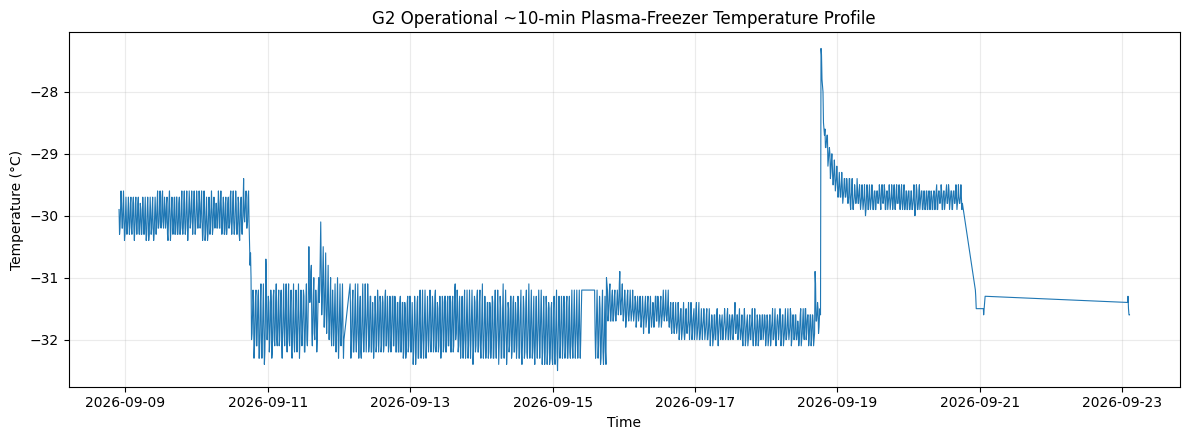

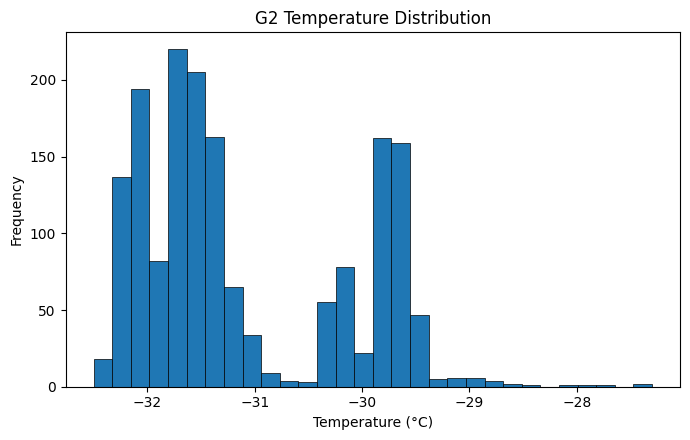

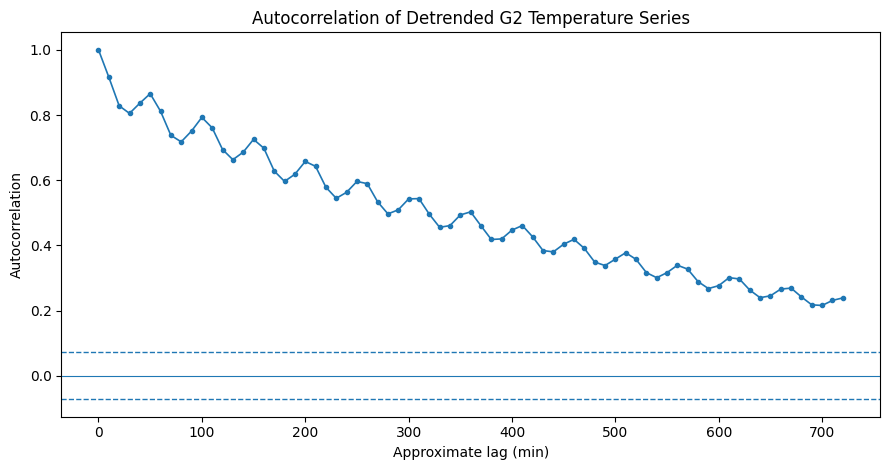

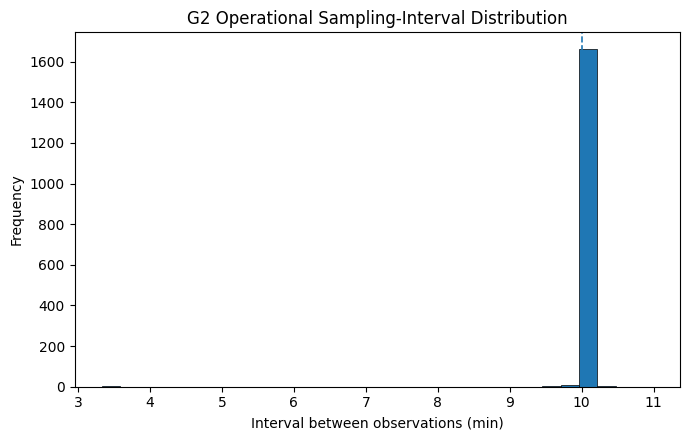


G2 FINAL SUMMARY
                          Metric       Value
                               N 1686.000000
                  Duration_hours  340.663889
                   Duration_days   14.194329
             Median_interval_min   10.000000
               Mean_interval_min   12.130465
       Regular_8_12min_intervals 1675.000000
             Regular_8_12min_pct   99.406528
                  Number_of_gaps    5.000000
               Estimated_missing  362.000000
           Estimated_missing_pct   17.675781
              Temperature_mean_C  -31.092171
            Temperature_median_C  -31.500000
                Temperature_SD_C    0.972218
               Temperature_min_C  -32.500000
               Temperature_max_C  -27.300000
               Valid_10min_pairs 1675.000000
    Mean_absolute_10min_change_C    0.286388
     P95_absolute_10min_change_C    0.800000
 Maximum_absolute_10min_change_C    4.300000
    Longest_continuous_segment_N  745.000000
Longest_continuous_segment_hours  124

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

- G2_descriptive_statistics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (24 outputs left out)

- G2_sampling_interval_distribution.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


G2 ANALYSIS COMPLETED
No interpolation, resampling, or gap bridging was performed.
G2 was analyzed as the real operational ~10-min acquisition regime.


In [1]:
# ============================================================
# PAPER 02 - HRFEST 2026
# G2 ANALYSIS - REAL ~10-MIN OPERATIONAL ACQUISITION
#
# Objectives:
# 1. Validate G2
# 2. Quantify temporal coverage and sampling regularity
# 3. Characterize acquisition gaps / missing observations
# 4. Calculate descriptive statistics
# 5. Test normality
# 6. Characterize consecutive ~10-min temperature changes
# 7. Identify continuous ~10-min segments
# 8. Test stationarity (ADF + KPSS)
# 9. Linear detrending
# 10. ACF with 95% confidence bounds
# 11. Identify recurrent thermal patterns
#
# IMPORTANT:
# - No interpolation is performed.
# - No resampling is performed.
# - No gaps are bridged.
# - G2 is analyzed as an operational deployment dataset.
# ============================================================

!pip -q install statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.signal import detrend, find_peaks
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.tsa.stattools import adfuller, kpss, acf


# ============================================================
# 1. UPLOAD G2
# ============================================================

uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("\nFile uploaded:")
print(filename)


# ============================================================
# 2. READ DATASET
# ============================================================

df = pd.read_csv(filename)

datetime_col = "datetime"
temperature_col = "dsTemperature"

print("\n====================================================")
print("DATASET STRUCTURE")
print("====================================================")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nColumns:")
for c in df.columns:
    print("-", c)


# ============================================================
# 3. DATA TYPE CONVERSION
# ============================================================

df[datetime_col] = pd.to_datetime(
    df[datetime_col],
    errors="coerce",
    utc=True
)

df[temperature_col] = pd.to_numeric(
    df[temperature_col],
    errors="coerce"
)


invalid_datetime = df[datetime_col].isna().sum()
invalid_temperature = df[temperature_col].isna().sum()


print("\n====================================================")
print("VALIDATION")
print("====================================================")

print("Invalid datetime:", invalid_datetime)
print("Invalid temperature:", invalid_temperature)


df = (
    df
    .dropna(
        subset=[
            datetime_col,
            temperature_col
        ]
    )
    .sort_values(datetime_col)
    .drop_duplicates(
        subset=[datetime_col]
    )
    .reset_index(drop=True)
)


print(
    "Valid observations:",
    len(df)
)


# ============================================================
# 4. TEMPORAL INTERVALS
# ============================================================

df["interval_min"] = (
    df[datetime_col]
    .diff()
    .dt.total_seconds()
    / 60
)


start = df[datetime_col].min()
end = df[datetime_col].max()

duration_h = (
    end - start
).total_seconds() / 3600

duration_days = duration_h / 24


print("\n====================================================")
print("TEMPORAL COVERAGE")
print("====================================================")

print("N observations:", len(df))
print("Start:", start)
print("End:", end)

print(
    "Duration:",
    round(duration_h, 4),
    "hours"
)

print(
    "Duration:",
    round(duration_days, 4),
    "days"
)

print(
    "Median interval:",
    round(
        df["interval_min"].median(),
        4
    ),
    "min"
)

print(
    "Mean interval:",
    round(
        df["interval_min"].mean(),
        4
    ),
    "min"
)

print(
    "Minimum interval:",
    round(
        df["interval_min"].min(),
        4
    ),
    "min"
)

print(
    "Maximum interval:",
    round(
        df["interval_min"].max(),
        4
    ),
    "min"
)


# ============================================================
# 5. SAMPLING-REGULARITY ANALYSIS
# ============================================================
#
# Nominal G2 interval = 10 min.
#
# Operational intervals between 8 and 12 min are considered
# consistent with the nominal ~10-min regime.
# ============================================================

intervals = (
    df["interval_min"]
    .dropna()
)

regular_mask = (
    (intervals >= 8.0)
    &
    (intervals <= 12.0)
)

regular_count = int(
    regular_mask.sum()
)

regular_pct = (
    regular_mask.mean()
    * 100
)


print("\n====================================================")
print("SAMPLING REGULARITY")
print("====================================================")

print(
    "Intervals evaluated:",
    len(intervals)
)

print(
    "Intervals within 8-12 min:",
    regular_count
)

print(
    "Percentage within nominal regime:",
    round(
        regular_pct,
        4
    ),
    "%"
)


# Additional deviations around 10 min

absolute_interval_deviation = (
    intervals - 10
).abs()


print(
    "Median absolute deviation from 10 min:",
    round(
        absolute_interval_deviation.median(),
        4
    ),
    "min"
)

print(
    "95th percentile absolute deviation from 10 min:",
    round(
        absolute_interval_deviation.quantile(0.95),
        4
    ),
    "min"
)


# ============================================================
# 6. GAP / MISSING-DATA ANALYSIS
# ============================================================
#
# Gap threshold = 15 min
#
# Missing observations are estimated relative to the nominal
# 10-min acquisition interval.
# ============================================================

NOMINAL_INTERVAL = 10.0
GAP_THRESHOLD = 15.0


gaps = (
    df[
        df["interval_min"]
        > GAP_THRESHOLD
    ]
    .copy()
)


if len(gaps) > 0:

    gaps["estimated_missing"] = np.maximum(
        np.round(
            gaps["interval_min"]
            / NOMINAL_INTERVAL
        ).astype(int) - 1,
        0
    )

else:

    gaps["estimated_missing"] = []


estimated_missing = int(
    gaps["estimated_missing"].sum()
) if len(gaps) > 0 else 0


expected_total = (
    len(df)
    + estimated_missing
)


missing_pct = (
    estimated_missing
    / expected_total
    * 100
)


print("\n====================================================")
print("GAP / MISSING-DATA ANALYSIS")
print("====================================================")

print(
    "Gap threshold:",
    GAP_THRESHOLD,
    "min"
)

print(
    "Number of gaps:",
    len(gaps)
)

print(
    "Estimated missing observations:",
    estimated_missing
)

print(
    "Expected observations:",
    expected_total
)

print(
    "Estimated missing percentage:",
    round(
        missing_pct,
        4
    ),
    "%"
)


if len(gaps) > 0:

    print(
        "Maximum gap:",
        round(
            gaps["interval_min"].max(),
            4
        ),
        "min"
    )

    print(
        "Median gap:",
        round(
            gaps["interval_min"].median(),
            4
        ),
        "min"
    )

    print("\nLargest gaps:")

    print(
        gaps[
            [
                datetime_col,
                "interval_min",
                "estimated_missing"
            ]
        ]
        .sort_values(
            "interval_min",
            ascending=False
        )
        .to_string(index=False)
    )


# ============================================================
# 7. DESCRIPTIVE STATISTICS
# ============================================================

temp = df[temperature_col]


descriptive = pd.DataFrame({

    "Statistic": [
        "N",
        "Mean",
        "Median",
        "Standard deviation",
        "Minimum",
        "Maximum",
        "Range",
        "Q1",
        "Q3",
        "IQR"
    ],

    "Value": [
        len(temp),
        temp.mean(),
        temp.median(),
        temp.std(ddof=1),
        temp.min(),
        temp.max(),
        temp.max() - temp.min(),
        temp.quantile(0.25),
        temp.quantile(0.75),
        temp.quantile(0.75)
        - temp.quantile(0.25)
    ]
})


print("\n====================================================")
print("DESCRIPTIVE STATISTICS")
print("====================================================")

print(
    descriptive
    .to_string(index=False)
)


# ============================================================
# 8. TEMPERATURE PERCENTILES
# ============================================================

percentiles = temp.quantile(
    [
        0.01,
        0.05,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)


print("\n====================================================")
print("TEMPERATURE PERCENTILES")
print("====================================================")

print(percentiles)


# ============================================================
# 9. LILLIEFORS NORMALITY TEST
# ============================================================

lillie_stat, lillie_p = lilliefors(
    temp.values,
    dist="norm"
)


print("\n====================================================")
print("LILLIEFORS NORMALITY TEST")
print("====================================================")

print(
    "Statistic:",
    round(
        lillie_stat,
        6
    )
)

print(
    "p-value:",
    lillie_p
)


if lillie_p < 0.05:

    print(
        "Result: reject H0 -> "
        "temperature distribution is not normal."
    )

else:

    print(
        "Result: H0 is not rejected."
    )


# ============================================================
# 10. CONSECUTIVE ~10-MIN TEMPERATURE VARIATION
# ============================================================
#
# Only operational intervals between 8 and 12 min are used.
#
# This prevents large outages from being interpreted as
# ordinary consecutive 10-min temperature changes.
# ============================================================

df["delta_temp"] = (
    df[temperature_col]
    .diff()
)


valid_10min_pairs = (
    (df["interval_min"] >= 8.0)
    &
    (df["interval_min"] <= 12.0)
)


delta = (
    df.loc[
        valid_10min_pairs,
        "delta_temp"
    ]
    .dropna()
)


abs_delta = delta.abs()


print("\n====================================================")
print("CONSECUTIVE ~10-MIN TEMPERATURE VARIATION")
print("====================================================")

print(
    "Valid consecutive pairs:",
    len(delta)
)

print(
    "Mean signed change:",
    round(
        delta.mean(),
        6
    ),
    "°C"
)

print(
    "Mean absolute change:",
    round(
        abs_delta.mean(),
        6
    ),
    "°C"
)

print(
    "Median absolute change:",
    round(
        abs_delta.median(),
        6
    ),
    "°C"
)

print(
    "95th percentile absolute change:",
    round(
        abs_delta.quantile(0.95),
        6
    ),
    "°C"
)

print(
    "Maximum absolute change:",
    round(
        abs_delta.max(),
        6
    ),
    "°C"
)


thresholds = [
    0.1,
    0.2,
    0.3,
    0.5,
    1.0
]


variation_results = []


for threshold in thresholds:

    pct = (
        (abs_delta <= threshold)
        .mean()
        * 100
    )

    variation_results.append({
        "Threshold_C":
            threshold,

        "Pairs_within_threshold_pct":
            pct
    })


variation_table = pd.DataFrame(
    variation_results
)


print(
    "\nPercentage of consecutive "
    "~10-min changes within thresholds:"
)

print(
    variation_table
    .to_string(index=False)
)


# ============================================================
# 11. IDENTIFY CONTINUOUS ~10-MIN SEGMENTS
# ============================================================
#
# A new segment begins whenever an interval is outside
# 8-12 min.
#
# This is intentionally conservative.
# ============================================================

break_mask = (
    df["interval_min"].isna()
    |
    (df["interval_min"] < 8.0)
    |
    (df["interval_min"] > 12.0)
)


df["segment"] = (
    break_mask.cumsum()
)


segment_summary = (
    df.groupby("segment")
    .agg(
        N=(temperature_col, "size"),
        Start=(datetime_col, "min"),
        End=(datetime_col, "max")
    )
)


segment_summary["Duration_h"] = (
    (
        segment_summary["End"]
        -
        segment_summary["Start"]
    )
    .dt.total_seconds()
    / 3600
)


segment_summary = (
    segment_summary
    .sort_values(
        "N",
        ascending=False
    )
)


print("\n====================================================")
print("CONTINUOUS ~10-MIN SEGMENTS")
print("====================================================")

print(
    segment_summary
    .head(20)
)


largest_segment_id = (
    segment_summary.index[0]
)


continuous = (
    df[
        df["segment"]
        == largest_segment_id
    ]
    .copy()
    .reset_index(drop=True)
)


continuous_duration_h = (
    (
        continuous[datetime_col].max()
        -
        continuous[datetime_col].min()
    )
    .total_seconds()
    / 3600
)


print("\n====================================================")
print("LONGEST CONTINUOUS ~10-MIN SEGMENT")
print("====================================================")

print(
    "N:",
    len(continuous)
)

print(
    "Start:",
    continuous[datetime_col].min()
)

print(
    "End:",
    continuous[datetime_col].max()
)

print(
    "Duration:",
    round(
        continuous_duration_h,
        4
    ),
    "hours"
)


# ============================================================
# 12. STATIONARITY TESTS
# ============================================================

series = (
    continuous[temperature_col]
    .astype(float)
    .values
)


# ---------------- ADF ----------------

adf_result = adfuller(
    series,
    autolag="AIC"
)


adf_stat = adf_result[0]
adf_p = adf_result[1]


print("\n====================================================")
print("ADF STATIONARITY TEST")
print("====================================================")

print(
    "ADF statistic:",
    round(
        adf_stat,
        6
    )
)

print(
    "p-value:",
    adf_p
)

print(
    "Lags used:",
    adf_result[2]
)

print(
    "Observations:",
    adf_result[3]
)

print(
    "Critical values:",
    adf_result[4]
)


if adf_p < 0.05:

    print(
        "Interpretation: reject unit-root H0."
    )

else:

    print(
        "Interpretation: fail to reject "
        "unit-root H0."
    )


# ---------------- KPSS ----------------

kpss_result = kpss(
    series,
    regression="c",
    nlags="auto"
)


kpss_stat = kpss_result[0]
kpss_p = kpss_result[1]


print("\n====================================================")
print("KPSS STATIONARITY TEST")
print("====================================================")

print(
    "KPSS statistic:",
    round(
        kpss_stat,
        6
    )
)

print(
    "p-value:",
    kpss_p
)

print(
    "Lags used:",
    kpss_result[2]
)

print(
    "Critical values:",
    kpss_result[3]
)


if kpss_p < 0.05:

    print(
        "Interpretation: reject "
        "level-stationarity H0."
    )

else:

    print(
        "Interpretation: fail to reject "
        "level-stationarity H0."
    )


# ============================================================
# 13. LINEAR DETRENDING
# ============================================================

detrended = detrend(
    series,
    type="linear"
)


continuous[
    "temperature_detrended"
] = detrended


print("\n====================================================")
print("LINEAR DETRENDING")
print("====================================================")

print(
    "Original mean:",
    round(
        np.mean(series),
        6
    )
)

print(
    "Detrended mean:",
    round(
        np.mean(detrended),
        10
    )
)


# ============================================================
# 14. ACF
# ============================================================
#
# Each lag corresponds approximately to 10 min.
#
# 72 lags = approximately 12 hours.
# ============================================================

MAX_LAG = min(
    72,
    len(detrended) - 1
)


acf_values = acf(
    detrended,
    nlags=MAX_LAG,
    fft=True
)


confidence_95 = (
    1.96
    / np.sqrt(
        len(detrended)
    )
)


lag_number = np.arange(
    len(acf_values)
)


lag_minutes = (
    lag_number
    * 10
)


print("\n====================================================")
print("G2 ACF ANALYSIS")
print("====================================================")

print(
    "N used:",
    len(detrended)
)

print(
    "Maximum lag:",
    MAX_LAG,
    "observations"
)

print(
    "Approximate maximum lag:",
    MAX_LAG * 10,
    "min"
)

print(
    "Approximate 95% confidence threshold:",
    round(
        confidence_95,
        6
    )
)


# ============================================================
# 15. ACF PEAK DETECTION
# ============================================================
#
# Search positive peaks after lag 1.
#
# Minimum peak separation = 3 observations ≈ 30 min.
# ============================================================

search_values = (
    acf_values.copy()
)

search_values[:2] = 0


peaks, properties = find_peaks(
    search_values,
    height=confidence_95,
    distance=3,
    prominence=0.03
)


peak_table = pd.DataFrame({

    "Lag_observations":
        peaks,

    "Approx_lag_min":
        peaks * 10,

    "ACF":
        acf_values[peaks]
})


print("\n====================================================")
print("SIGNIFICANT POSITIVE G2 ACF PEAKS")
print("====================================================")


if len(peak_table) > 0:

    print(
        peak_table
        .to_string(index=False)
    )

else:

    print(
        "No positive peaks meeting the "
        "specified criteria were detected."
    )


# ============================================================
# 16. G2 TEMPERATURE PROFILE
# ============================================================

plt.figure(
    figsize=(12, 4.5)
)

plt.plot(
    df[datetime_col],
    df[temperature_col],
    linewidth=0.8
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")

plt.title(
    "G2 Operational ~10-min Plasma-Freezer Temperature Profile"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "G2_temperature_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 17. G2 TEMPERATURE HISTOGRAM
# ============================================================

plt.figure(
    figsize=(7, 4.5)
)

plt.hist(
    temp,
    bins=30,
    edgecolor="black",
    linewidth=0.5
)

plt.xlabel(
    "Temperature (°C)"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "G2 Temperature Distribution"
)

plt.tight_layout()

plt.savefig(
    "G2_temperature_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18. G2 ACF FIGURE
# ============================================================

plt.figure(
    figsize=(9, 4.8)
)

plt.plot(
    lag_minutes,
    acf_values,
    marker="o",
    markersize=3,
    linewidth=1.2
)

plt.axhline(
    confidence_95,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    -confidence_95,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    0,
    linewidth=0.8
)

plt.xlabel(
    "Approximate lag (min)"
)

plt.ylabel(
    "Autocorrelation"
)

plt.title(
    "Autocorrelation of Detrended G2 Temperature Series"
)

plt.tight_layout()

plt.savefig(
    "G2_ACF_detrended.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 19. INTERVAL-DISTRIBUTION FIGURE
# ============================================================
#
# Plot only intervals <= 20 min so large outages do not
# compress the operational interval distribution.
# ============================================================

interval_plot = intervals[
    intervals <= 20
]


plt.figure(
    figsize=(7, 4.5)
)

plt.hist(
    interval_plot,
    bins=30,
    edgecolor="black",
    linewidth=0.5
)

plt.axvline(
    10,
    linestyle="--",
    linewidth=1.2
)

plt.xlabel(
    "Interval between observations (min)"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "G2 Operational Sampling-Interval Distribution"
)

plt.tight_layout()

plt.savefig(
    "G2_sampling_interval_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 20. SUMMARY TABLE
# ============================================================

summary = pd.DataFrame({

    "Metric": [

        "N",
        "Duration_hours",
        "Duration_days",

        "Median_interval_min",
        "Mean_interval_min",

        "Regular_8_12min_intervals",
        "Regular_8_12min_pct",

        "Number_of_gaps",
        "Estimated_missing",
        "Estimated_missing_pct",

        "Temperature_mean_C",
        "Temperature_median_C",
        "Temperature_SD_C",
        "Temperature_min_C",
        "Temperature_max_C",

        "Valid_10min_pairs",
        "Mean_absolute_10min_change_C",
        "P95_absolute_10min_change_C",
        "Maximum_absolute_10min_change_C",

        "Longest_continuous_segment_N",
        "Longest_continuous_segment_hours",

        "Lilliefors_statistic",
        "Lilliefors_p",

        "ADF_statistic",
        "ADF_p",

        "KPSS_statistic",
        "KPSS_p"
    ],

    "Value": [

        len(df),
        duration_h,
        duration_days,

        intervals.median(),
        intervals.mean(),

        regular_count,
        regular_pct,

        len(gaps),
        estimated_missing,
        missing_pct,

        temp.mean(),
        temp.median(),
        temp.std(ddof=1),
        temp.min(),
        temp.max(),

        len(delta),
        abs_delta.mean(),
        abs_delta.quantile(0.95),
        abs_delta.max(),

        len(continuous),
        continuous_duration_h,

        lillie_stat,
        lillie_p,

        adf_stat,
        adf_p,

        kpss_stat,
        kpss_p
    ]
})


print("\n====================================================")
print("G2 FINAL SUMMARY")
print("====================================================")

print(
    summary
    .to_string(index=False)
)


# ============================================================
# 21. EXPORT RESULTS
# ============================================================

descriptive.to_csv(
    "G2_descriptive_statistics.csv",
    index=False
)

variation_table.to_csv(
    "G2_10min_variation.csv",
    index=False
)

gaps.to_csv(
    "G2_gap_analysis.csv",
    index=False
)

segment_summary.to_csv(
    "G2_continuous_segments.csv"
)

peak_table.to_csv(
    "G2_ACF_peaks.csv",
    index=False
)

summary.to_csv(
    "G2_analysis_summary.csv",
    index=False
)


test_results = pd.DataFrame({

    "Test": [
        "Lilliefors",
        "ADF",
        "KPSS"
    ],

    "Statistic": [
        lillie_stat,
        adf_stat,
        kpss_stat
    ],

    "p_value": [
        lillie_p,
        adf_p,
        kpss_p
    ]
})


test_results.to_csv(
    "G2_statistical_tests.csv",
    index=False
)


# ============================================================
# 22. DOWNLOAD RESULTS
# ============================================================

files_to_download = [

    "G2_analysis_summary.csv",
    "G2_descriptive_statistics.csv",
    "G2_10min_variation.csv",
    "G2_gap_analysis.csv",
    "G2_continuous_segments.csv",
    "G2_ACF_peaks.csv",
    "G2_statistical_tests.csv",

    "G2_temperature_profile.png",
    "G2_temperature_histogram.png",
    "G2_ACF_detrended.png",
    "G2_sampling_interval_distribution.png"
]


print("\n====================================================")
print("FILES GENERATED")
print("====================================================")

for f in files_to_download:

    print("-", f)

    files.download(f)


print("\n====================================================")
print("G2 ANALYSIS COMPLETED")
print("====================================================")

print(
    "No interpolation, resampling, or gap bridging "
    "was performed."
)

print(
    "G2 was analyzed as the real operational "
    "~10-min acquisition regime."
)